# SSL + classical feature fusion with GraphDitty

For a few songs, this notebook:

1. Extracts the SSL features (MuQ, MusicFM, MULE, MATPAC, RepCL) and the classical
   *partner* features (STM and MFCC by default) with `pipeline.extract_all`.
2. Shows the per-feature SSMs.
3. Fuses every SSL SSM with every partner SSM, **one partner at a time** (MuQ-STM,
   MusicFM-STM, ..., RepCL-STM, then MuQ-MFCC, ...), using GraphDitty similarity network
   fusion, and shows the fused SSMs.
4. Segments every SSM (single features and fusions) with the configured algorithms and
   compares boundary F-measure at 0.5 s and 3 s against the ground truth.

Segmentation, the JAMS outputs and the fused SSMs come from `run_structure_baseline.process_feature_data`.
Evaluation comes from `evaluate_structure_baseline.evaluate_jams`. The notebook itself only
adds the feature cache and the plots.

To fuse the SSL features with another feature, edit `PARTNER_FEATURES` in the parameters cell.
For example, `["chroma", "mfcc"]` replaces STM with chroma.

In [1]:
from __future__ import annotations

import json
import os
import sys
from dataclasses import replace
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
for candidate in (
    PROJECT_DIR,
    PROJECT_DIR.parent,
    PROJECT_DIR / "MSA-with-Interpretable-Features",
    PROJECT_DIR / "tesis/msa/MSA-with-Interpretable-Features",
    PROJECT_DIR / "maestria/tesis/msa/MSA-with-Interpretable-Features",
):
    if (candidate / "run_structure_baseline.py").exists():
        PROJECT_DIR = candidate.resolve()
        break
else:
    raise FileNotFoundError("Run this notebook from MSA-with-Interpretable-Features, its experiments folder, or a parent folder.")

# The scripts place their caches under ./.cache and resolve relative paths against the repo.
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from data_loading import normalize_computing_features
from evaluate_structure_baseline import (
    BOUNDARY_F1_METRICS,
    GRIDLINE,
    SECONDARY_INK,
    algorithm_colors,
    evaluate_jams,
    plot_grouped_metric,
)
from pipeline import extract_all
from run_structure_baseline import (
    algorithm_slug,
    build_feature_config,
    list_audio_files,
    load_config,
    parse_args,
    parse_segmentation_config,
    process_feature_data,
)
from segmentation import SSM_FEATURE_TO_KEY, build_ssm_runs, load_ssm, normalize_algorithms

## Parameters

In [25]:
# Same YAML used by run_structure_baseline.py: audio_dir, sections_dir, beat tracking, SSM
# similarity, SSL device, segmentation algorithms and GraphDitty parameters come from here.

# CONFIG_PATH = PROJECT_DIR / "configs/rwcpop_config.template.yaml"
CONFIG_PATH = PROJECT_DIR / "configs/harmonix_config.template.yaml"

# Track ids (audio file stems inside `audio_dir`).
# TRACK_IDS = ["RM-P001", "RM-P002", "RM-P003"]
TRACK_IDS = ["0021_better", "0217_pokerface", "0764_iwish"]

SSL_FEATURES = ["muq", "musicfm", "mule", "matpac", "repcl"]

# Each partner is fused separately with every SSL feature: <SSL>-<partner> pairs.
# Swap "stm" for any other feature (chroma, cens, tonnetz, arrangement, ...) to change it.
PARTNER_FEATURES = ["chroma", "mfcc"]

# Also segment each feature alone, as the baseline the fusions are compared against.
INCLUDE_SINGLE_FEATURES = True

# None -> take them from the config (`segmentation.algorithms`, `segmentation.graphditty_fusion`).
ALGORITHMS = None  # e.g. [{"id": "foote", "source": "msaf", "params": {"M_gaussian": 66, "L_peaks": 64}}]
GRAPHDITTY_FUSION = None  # e.g. {"k": 5, "niters": 20, "reg_diag": 1.0, "reg_neighbs": 0.5}
SSL_DEVICE = None  # None -> `feature_config.ssl_device` from the config ("cuda" / "cpu")

# Extracted features are cached here; changing PARTNER_FEATURES only extracts the new ones.
FEATURE_CACHE_DIR = PROJECT_DIR / "feature_outputs/ssl_partner_fusion_notebook"
# JAMS outputs, fused SSMs (fusion_ssms/) and result plots (results/) go here.
EXPERIMENT_DIR = PROJECT_DIR / "experiments/ssl_partner_fusion_notebook"

In [26]:
raw_config = load_config(CONFIG_PATH)
segmentation_cfg = parse_segmentation_config(raw_config)

REQUIRED_FEATURES = list(dict.fromkeys([*SSL_FEATURES, *PARTNER_FEATURES]))
feature_cfg = build_feature_config(parse_args(["--config", str(CONFIG_PATH)]), raw_config)
feature_cfg = replace(
    feature_cfg,
    computing_features=normalize_computing_features([*REQUIRED_FEATURES, "sections"]),
    ssl_device=SSL_DEVICE or feature_cfg.ssl_device,
)
if feature_cfg.sections_dir is None:
    raise ValueError("Set `feature_config.sections_dir` in the config: the F-measure needs ground truth.")

algorithms = normalize_algorithms(ALGORITHMS if ALGORITHMS is not None else segmentation_cfg.get("algorithms"))
fusion_cfg = dict(GRAPHDITTY_FUSION if GRAPHDITTY_FUSION is not None else segmentation_cfg.get("graphditty_fusion", {}))
fusion_combos = [[ssl, partner] for partner in PARTNER_FEATURES for ssl in SSL_FEATURES]
ssm_runs = build_ssm_runs(REQUIRED_FEATURES if INCLUDE_SINGLE_FEATURES else [], fusion_combos)

DISPLAY_NAMES = {"muq": "MuQ", "musicfm": "MusicFM", "mule": "MULE", "matpac": "MATPAC", "repcl": "RepCL", "chroma": "Chroma", "cens": "CENS", "tonnetz": "Tonnetz"}


def display_name(feature: str) -> str:
    return DISPLAY_NAMES.get(feature, feature.upper())


RUN_FEATURES = dict(ssm_runs)
RUN_DISPLAY = {label: "-".join(display_name(feature) for feature in features) for label, features in ssm_runs}
RUN_ORDER = [RUN_DISPLAY[label] for label, _ in ssm_runs]
ALGORITHM_SLUGS = [algorithm_slug(algorithm) for algorithm in algorithms]
ALGORITHM_COLORS = algorithm_colors(ALGORITHM_SLUGS)

audio_dir = Path(raw_config["audio_dir"]).expanduser()
audio_by_stem = {path.stem: path for path in list_audio_files(audio_dir, None)}
missing_tracks = [track_id for track_id in TRACK_IDS if track_id not in audio_by_stem]
if missing_tracks:
    raise FileNotFoundError(f"No audio for {missing_tracks} in {audio_dir}")
audio_paths = {track_id: audio_by_stem[track_id] for track_id in TRACK_IDS}

print(f"Tracks: {', '.join(TRACK_IDS)}")
print(f"Features: {', '.join(map(display_name, REQUIRED_FEATURES))}  (SSM similarity: {feature_cfg.ssm_similarity_type})")
print(f"Algorithms: {', '.join(ALGORITHM_SLUGS)}")
print(f"SSM runs ({len(ssm_runs)}): {', '.join(RUN_ORDER)}")

Tracks: 0021_better, 0217_pokerface, 0764_iwish
Features: MuQ, MusicFM, MULE, MATPAC, RepCL, Chroma, MFCC  (SSM similarity: rbf)
Algorithms: as_seg_cbm, msaf_foote, msaf_scluster
SSM runs (17): MuQ, MusicFM, MULE, MATPAC, RepCL, Chroma, MFCC, MuQ-Chroma, MusicFM-Chroma, MULE-Chroma, MATPAC-Chroma, RepCL-Chroma, MuQ-MFCC, MusicFM-MFCC, MULE-MFCC, MATPAC-MFCC, RepCL-MFCC


## 1. Feature extraction

A track's cached npz is reused when it holds every requested SSM and was extracted with the same
config (sample rate, beat tracking, SSM similarity, STM/MULE parameters). If some features are
missing, only those are extracted and merged into the npz. If the beat grid comes out different,
everything is extracted again so all SSMs stay on the same grid.

In [27]:
# Config fields that change the beat grid or the SSM values; a cached npz is reused only if they match.
CACHE_CFG_FIELDS = (
    "sr", "hop_length", "n_fft", "n_mels", "n_mfcc", "beat_tracking_method", "ssm_similarity_type",
    "ssm_similarity_gamma", "stm_coeffs", "stm_window_s", "stm_hop_s", "stm_min_beats", "mule_hop_frames",
)


def cache_fingerprint(cfg) -> str:
    return json.dumps({name: getattr(cfg, name) for name in CACHE_CFG_FIELDS}, sort_keys=True, default=str)


def ssm_key(feature: str) -> str:
    return SSM_FEATURE_TO_KEY.get(feature, f"ssm_{feature}")


def feature_npz_for(audio_path: Path) -> Path:
    # Return a cached *_features.npz with every REQUIRED_FEATURES SSM, extracting only what is missing.
    FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    npz_path = FEATURE_CACHE_DIR / f"{audio_path.stem}_features.npz"
    fingerprint = cache_fingerprint(feature_cfg)

    cached: dict = {}
    if npz_path.exists():
        with np.load(npz_path, allow_pickle=True) as data:
            cached = {key: data[key] for key in data.files}
        if str(np.asarray(cached.get("notebook_cfg", "")).item()) != fingerprint:
            print("  cache was extracted with another config; extracting everything again")
            cached = {}

    missing = [feature for feature in REQUIRED_FEATURES if ssm_key(feature) not in cached]
    if not missing:
        print(f"  cached: {npz_path.name}")
        return npz_path

    print(f"  extracting: {', '.join(map(display_name, missing))}")
    cfg = replace(feature_cfg, computing_features=normalize_computing_features([*missing, "sections"]))
    _, payload = extract_all(audio_path, None, cfg, return_payload=True)
    if cached and not np.array_equal(np.asarray(cached["beat_boundaries"]), np.asarray(payload["beat_boundaries"])):
        print("  beat grid changed; extracting every feature again")
        _, payload = extract_all(audio_path, None, feature_cfg, return_payload=True)
        cached = {}
    np.savez_compressed(npz_path, **{**cached, **payload, "notebook_cfg": fingerprint})
    return npz_path


feature_npzs: dict[str, Path] = {}
for track_id, audio_path in audio_paths.items():
    print(track_id)
    feature_npzs[track_id] = feature_npz_for(audio_path)

0021_better
  extracting: Chroma
0217_pokerface
  extracting: Chroma
0764_iwish
  extracting: Chroma


## 2. Per-feature SSMs

Each SSM has gone through `segmentation.load_ssm`, which symmetrizes it and rescales the
5th–95th percentile to [0, 1], so this is exactly the matrix the segmentation algorithms receive.
Axes are beat indices. Dashed lines mark the ground-truth section boundaries.

In [28]:
SSM_CMAP = "Blues"  # single-hue sequential: darker = more similar
GT_COLOR = "#eb6834"


def load_track(track_id: str) -> dict:
    with np.load(feature_npzs[track_id], allow_pickle=True) as data:
        track = {key: data[key] for key in data.files}
    track["ssms"] = {feature: load_ssm(track, feature) for feature in REQUIRED_FEATURES}
    beats = np.asarray(track["beat_boundaries"])
    sections = track.get("sections", np.empty((0, 3)))
    duration = float(np.asarray(track["duration"]).item())
    # Internal ground-truth boundaries (excluding the track start and end), in seconds and beat indices.
    gt_times = sorted({float(t) for start, end, _ in sections for t in (start, end) if 0.0 < float(t) < duration - 1e-3})
    track["gt_times"] = np.asarray(gt_times)
    track["gt_beats"] = np.clip(np.searchsorted(beats, gt_times), 0, len(beats) - 1)
    return track


def show_ssm(ax, matrix: np.ndarray, title: str, gt_beats: np.ndarray) -> None:
    ax.imshow(matrix, origin="lower", cmap=SSM_CMAP, vmin=0.0, vmax=1.0, interpolation="nearest")
    for idx in gt_beats:
        ax.axvline(idx, color=GT_COLOR, linestyle="--", linewidth=0.7, alpha=0.8)
        ax.axhline(idx, color=GT_COLOR, linestyle="--", linewidth=0.7, alpha=0.8)
    ax.set_title(title, fontsize=10)
    ax.tick_params(labelsize=7)


tracks = {track_id: load_track(track_id) for track_id in TRACK_IDS}

for track_id, track in tracks.items():
    panels = [(display_name(feature), track["ssms"][feature]) for feature in REQUIRED_FEATURES]
    if "ssm_sections" in track:
        panels.append(("Ground truth (same label)", np.asarray(track["ssm_sections"])))
    n_cols = 4
    n_rows = int(np.ceil(len(panels) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 3.6 * n_rows), constrained_layout=True)
    for ax, (title, matrix) in zip(axes.ravel(), panels):
        show_ssm(ax, matrix, title, track["gt_beats"])
    for ax in axes.ravel()[len(panels):]:
        ax.axis("off")
    fig.suptitle(f"{track_id}: per-feature SSMs ({track['ssms'][REQUIRED_FEATURES[0]].shape[0]} beats)", fontsize=12)
    plt.show()

## 3. Segmentation (and GraphDitty fusion)

`process_feature_data` builds each run's SSM (fusing it with GraphDitty when the run has two
features), runs every algorithm on it and writes `<EXPERIMENT_DIR>/<algorithm>__<run>/<track>.jams`.
The fused SSMs go to `<EXPERIMENT_DIR>/fusion_ssms/`.
`scluster` works on a single raw feature, so it only runs on the single-feature runs.

In [29]:
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
seg_rows = []
for track_id, npz_path in feature_npzs.items():
    print(f"{track_id}: segmenting {len(ssm_runs)} SSM runs x {len(algorithms)} algorithms")
    with np.load(npz_path, allow_pickle=True) as data:
        seg_rows.extend(process_feature_data(data, str(npz_path), EXPERIMENT_DIR, algorithms, ssm_runs, fusion_cfg))
print(f"{len(seg_rows)} segmentations written to {EXPERIMENT_DIR}")

0021_better: segmenting 17 SSM runs x 3 algorithms
0217_pokerface: segmenting 17 SSM runs x 3 algorithms
0764_iwish: segmenting 17 SSM runs x 3 algorithms
123 segmentations written to /home/emartinez/maestria/tesis/msa/MSA-with-Interpretable-Features/experiments/ssl_partner_fusion_notebook


## 4. Fused SSMs

One row per partner feature. The first column is the partner SSM alone and the rest are its
GraphDitty fusions with each SSL feature. Each panel is the matrix the algorithms segmented
(read back from `fusion_ssms/`).

In [30]:
def load_fused_ssm(track_id: str, run_label: str) -> np.ndarray:
    with np.load(EXPERIMENT_DIR / "fusion_ssms" / f"{track_id}__{run_label}_fused_ssm.npz", allow_pickle=True) as data:
        return np.asarray(data["ssm_fused"])


for track_id, track in tracks.items():
    n_cols = 1 + len(SSL_FEATURES)
    fig, axes = plt.subplots(
        len(PARTNER_FEATURES), n_cols, figsize=(3.2 * n_cols, 3.3 * len(PARTNER_FEATURES)),
        constrained_layout=True, squeeze=False,
    )
    for row, partner in enumerate(PARTNER_FEATURES):
        show_ssm(axes[row, 0], track["ssms"][partner], f"{display_name(partner)} (alone)", track["gt_beats"])
        for col, ssl in enumerate(SSL_FEATURES, start=1):
            label = "fused_" + "-".join([ssl, partner])
            show_ssm(axes[row, col], load_fused_ssm(track_id, label), RUN_DISPLAY[label], track["gt_beats"])
    fig.suptitle(f"{track_id}: GraphDitty fusion of each SSL SSM with each partner", fontsize=12)
    plt.show()

## 5. Boundary F-measure

`evaluate_structure_baseline.evaluate_jams` scores each JAMS against the ground truth, using
`mir_eval.segment.detection` with `trim=True` (the track start and end are not counted) and
hit windows of 0.5 s and 3 s.

In [31]:
METRIC_LABELS = {"boundary_f_0_5s": "F@0.5s", "boundary_f_3_0s": "F@3s"}

eval_rows = []
for row in seg_rows:
    result = evaluate_jams(Path(row["jams"]), feature_cfg.sections_dir, feature_cfg.label_format)
    if result is None:
        print(f"skipped (no estimate or ground truth): {row['jams']}")
        continue
    metrics, _hits = result
    eval_rows.append(
        {
            "track_id": row["track_id"],
            "algorithm": row["algorithm"],
            "ssm_run": row["ssm_run"],
            "run": RUN_DISPLAY[row["ssm_run"]],
            "n_boundaries": row["n_boundaries"],
            "n_ref_boundaries": row["n_ref_boundaries"],
            "boundary_times": json.loads(Path(row["jams"]).read_text())["annotations"][0]["sandbox"]["boundary_times"],
            **{metric: metrics[metric] for metric in BOUNDARY_F1_METRICS},
        }
    )
eval_df = pd.DataFrame(eval_rows)
eval_df["run"] = pd.Categorical(eval_df["run"], categories=RUN_ORDER, ordered=True)
eval_df["algorithm"] = pd.Categorical(eval_df["algorithm"], categories=ALGORITHM_SLUGS, ordered=True)

results_dir = EXPERIMENT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)
eval_df.drop(columns="boundary_times").to_csv(results_dir / "boundary_f_detailed.csv", index=False)


def styled(table: pd.DataFrame):
    return table.style.format("{:.2f}", na_rep="–").background_gradient(cmap="Blues", vmin=0.0, vmax=1.0, axis=None)


for metric in BOUNDARY_F1_METRICS:
    per_track = eval_df.pivot_table(index="run", columns=["algorithm", "track_id"], values=metric, observed=True)
    mean = eval_df.pivot_table(index="run", columns="algorithm", values=metric, observed=True)
    for algorithm in mean.columns:
        per_track[(algorithm, "mean")] = mean[algorithm]
    per_track = per_track.sort_index(axis=1, level=0, sort_remaining=False)
    display(Markdown(f"### {METRIC_LABELS[metric]} per track (and mean over the {len(TRACK_IDS)} tracks)"))
    display(styled(per_track))

### F@0.5s per track (and mean over the 3 tracks)

### F@3s per track (and mean over the 3 tracks)

### Mean F-measure per algorithm, one chart per partner

Each chart has the single-feature baselines (each SSL feature and the partner alone) and the
fusions with that partner. Bars come from `evaluate_structure_baseline.plot_grouped_metric`.

#### Partner: Chroma

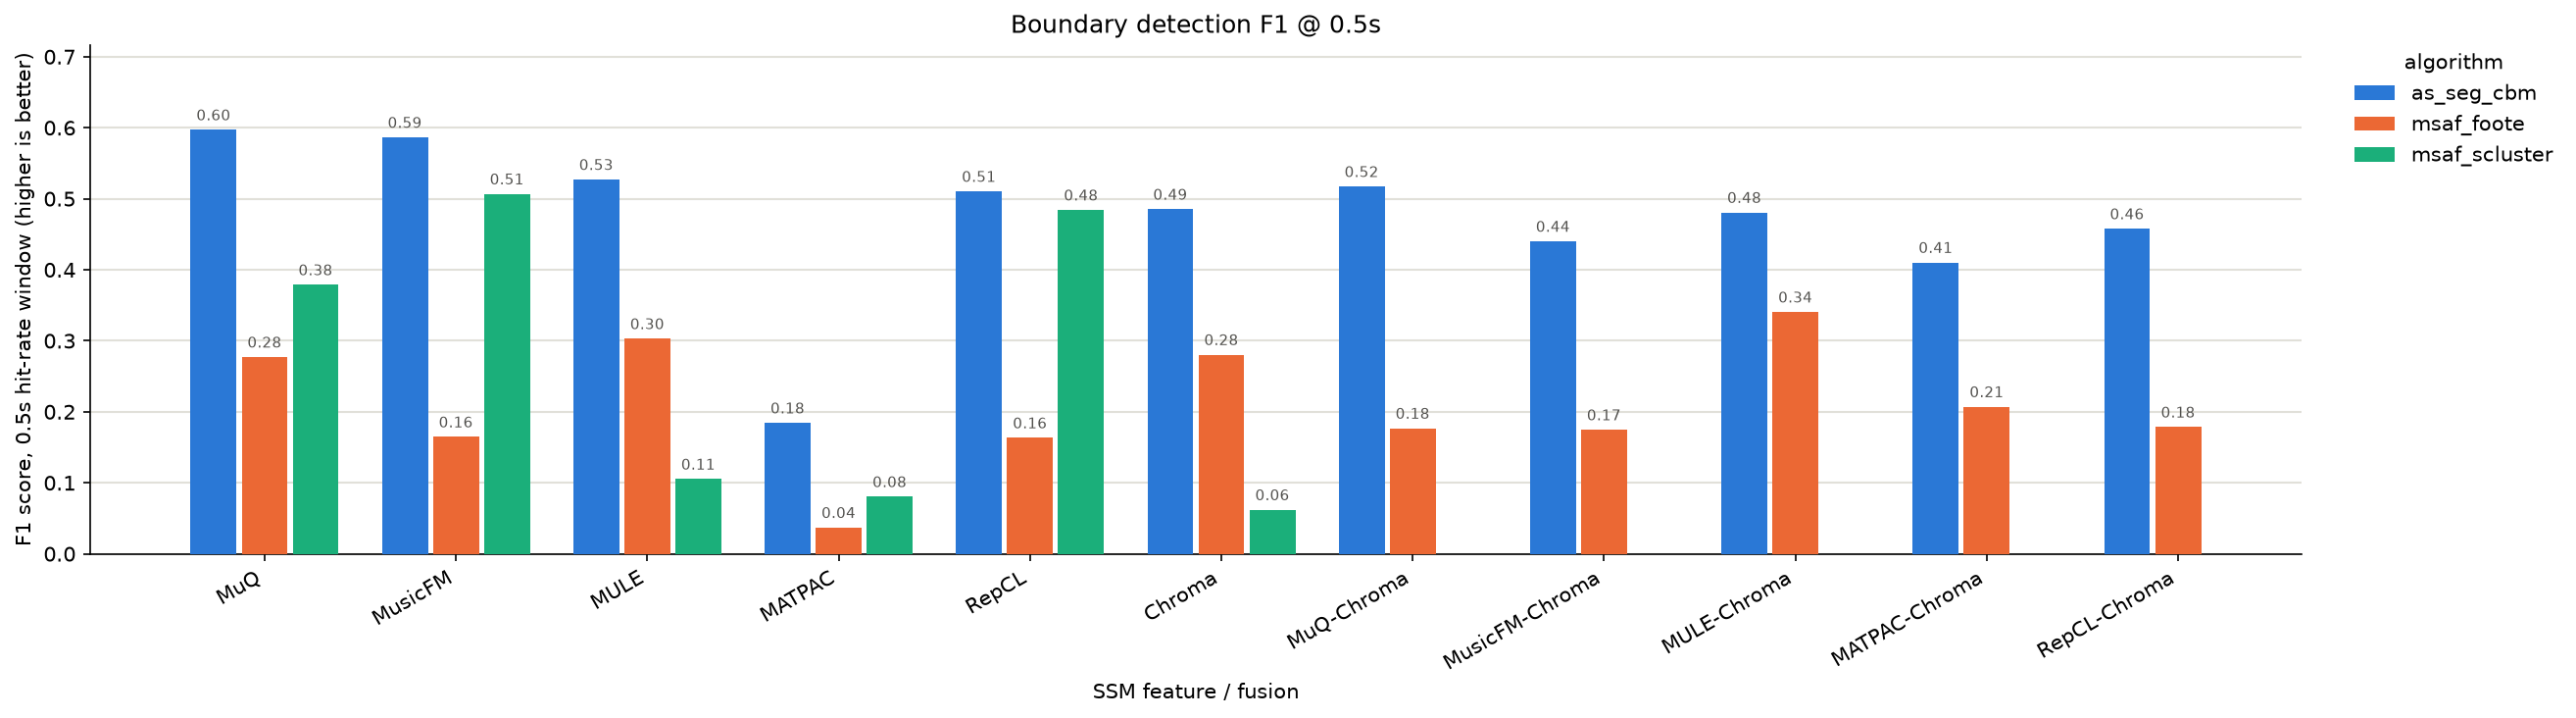

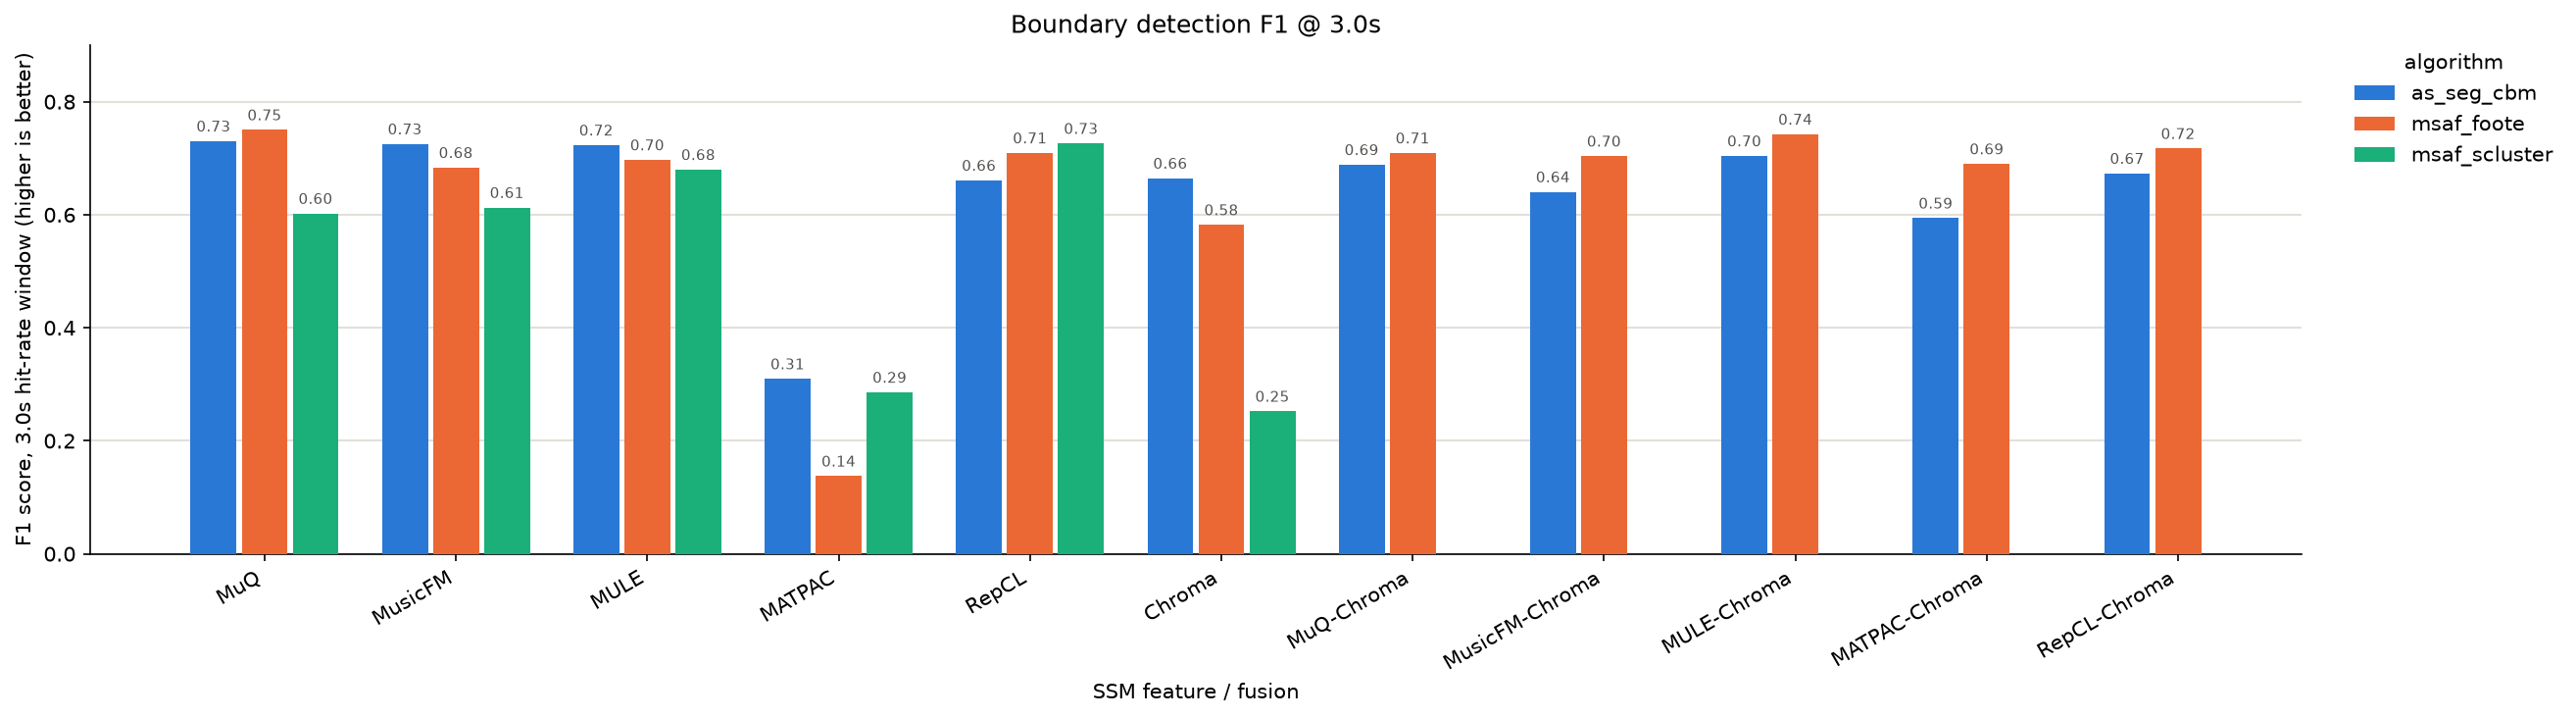

#### Partner: MFCC

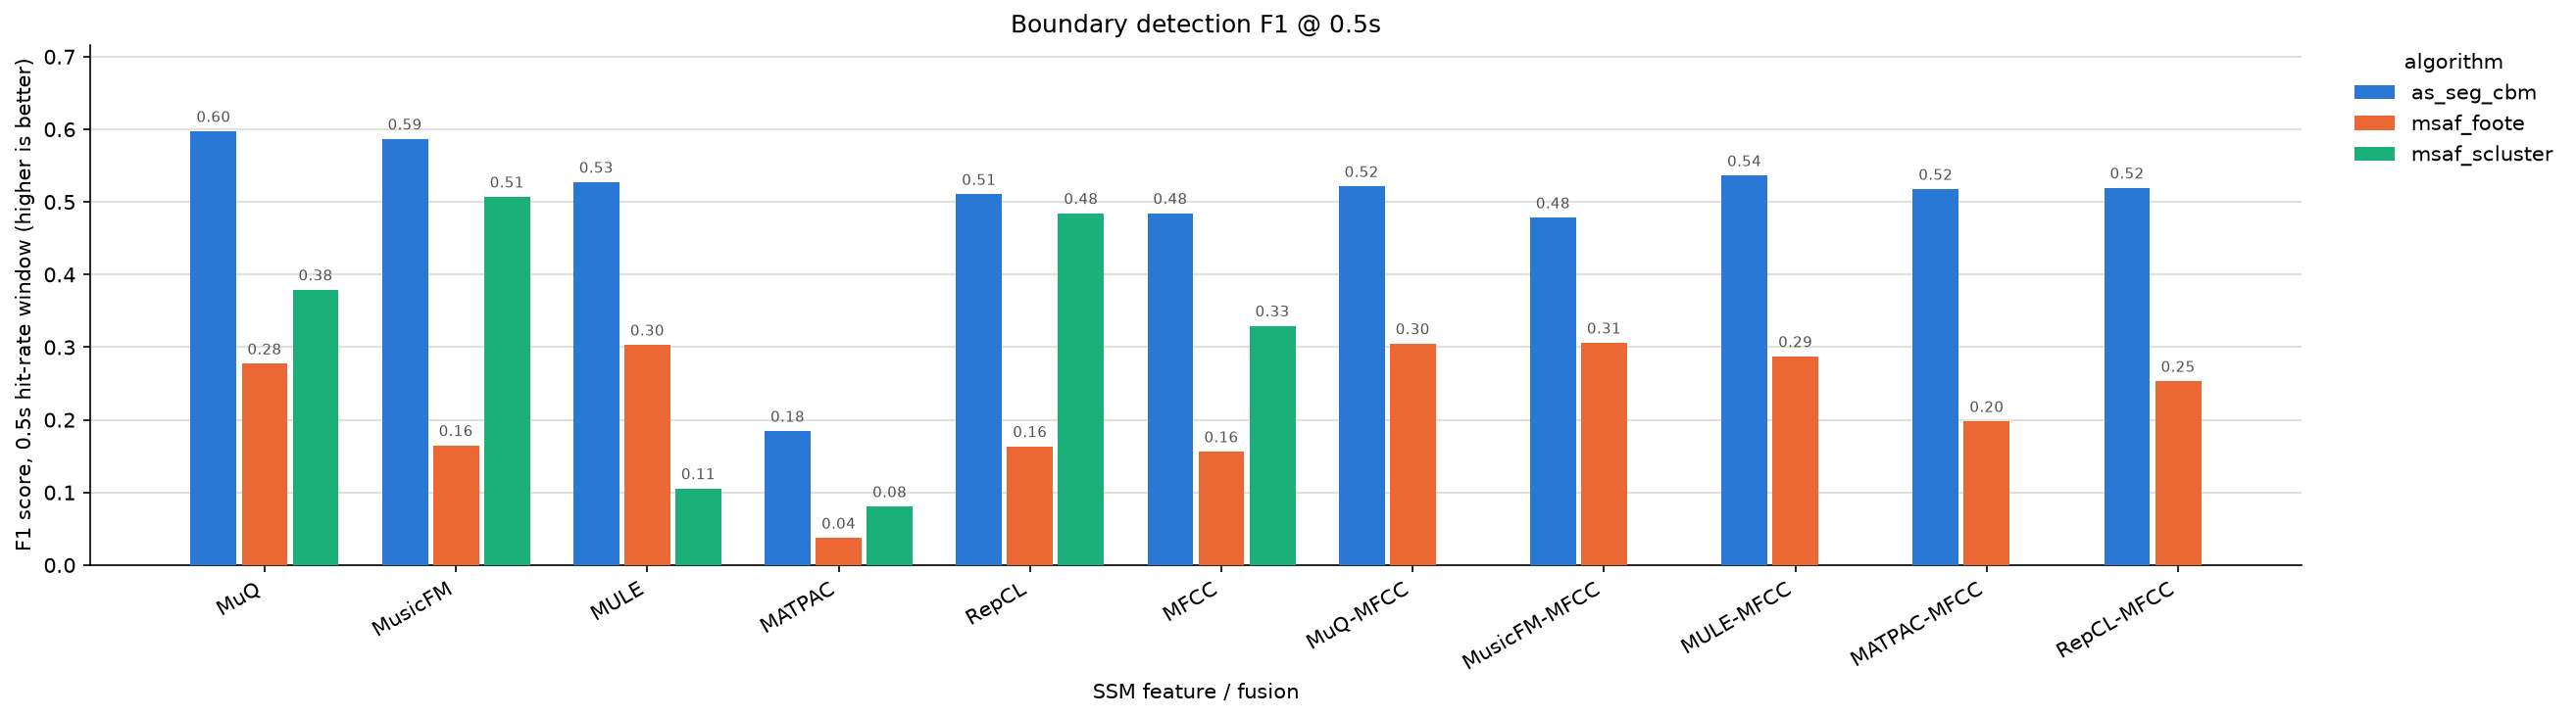

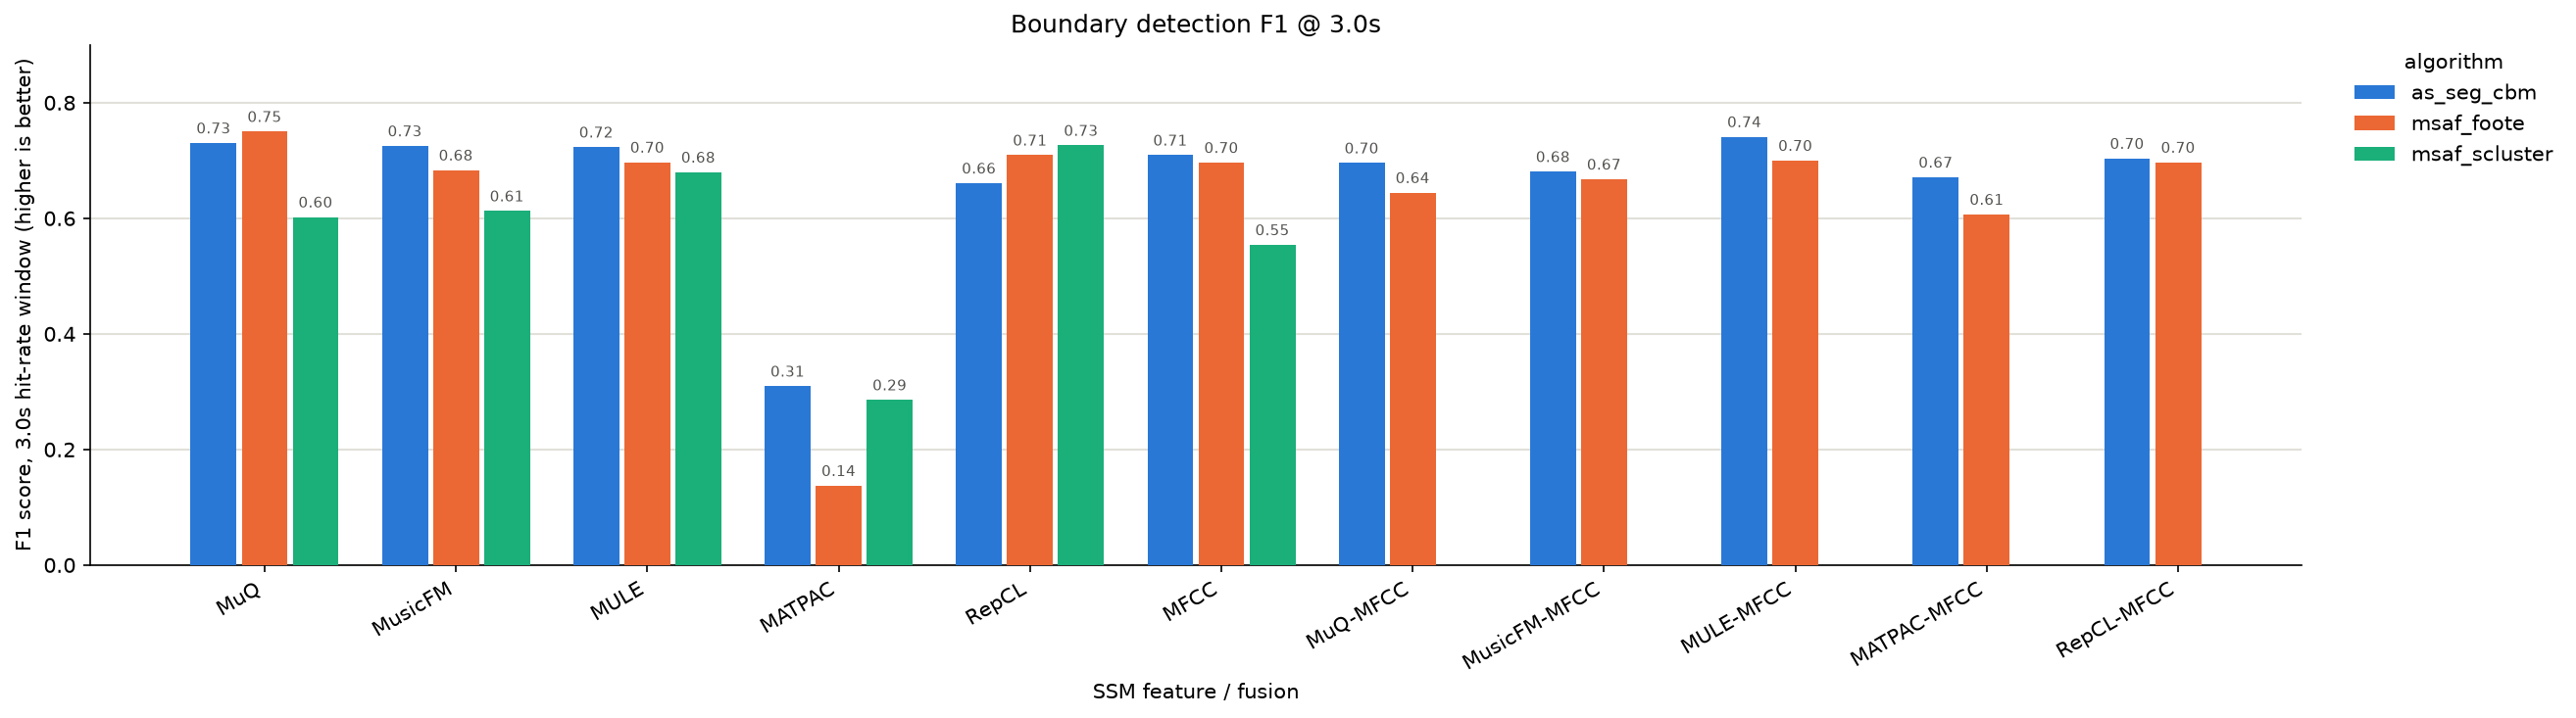

In [32]:
mean_df = (
    eval_df.groupby(["run", "algorithm"], observed=True)[list(BOUNDARY_F1_METRICS)].mean().reset_index()
    .rename(columns={"run": "ssm_run"})
)
for partner in PARTNER_FEATURES:
    runs = [RUN_DISPLAY[feature] for feature in [*SSL_FEATURES, partner] if feature in RUN_DISPLAY]
    runs += [RUN_DISPLAY["fused_" + "-".join([ssl, partner])] for ssl in SSL_FEATURES]
    subset = mean_df[mean_df["ssm_run"].isin(runs)].copy()
    subset["ssm_run"] = pd.Categorical(subset["ssm_run"].astype(str), categories=runs, ordered=True)
    partner_dir = results_dir / partner
    partner_dir.mkdir(parents=True, exist_ok=True)
    display(Markdown(f"#### Partner: {display_name(partner)}"))
    for metric in BOUNDARY_F1_METRICS:
        display(Image(filename=str(plot_grouped_metric(subset, metric, ALGORITHM_SLUGS, ALGORITHM_COLORS, partner_dir))))

### Fusion gain

For each SSL-partner fusion, its mean F-measure minus that of the SSL feature alone
(Δ vs SSL) and minus that of the partner alone (Δ vs partner). A positive value means
the fusion beats that feature on its own. Only algorithms that ran on both the single
and the fused SSMs are included, so `scluster` is left out.

In [24]:
if not INCLUDE_SINGLE_FEATURES:
    print("Set INCLUDE_SINGLE_FEATURES = True to compare the fusions against the single features.")
else:
    mean_by = eval_df.groupby(["ssm_run", "algorithm"], observed=True)[list(BOUNDARY_F1_METRICS)].mean()
    gain_rows = []
    for partner in PARTNER_FEATURES:
        for ssl in SSL_FEATURES:
            fused = "fused_" + "-".join([ssl, partner])
            for algorithm in ALGORITHM_SLUGS:
                if (fused, algorithm) not in mean_by.index:
                    continue
                row = {"partner": display_name(partner), "fusion": RUN_DISPLAY[fused], "algorithm": algorithm}
                for metric in BOUNDARY_F1_METRICS:
                    label = METRIC_LABELS[metric]
                    f_fused = mean_by.loc[(fused, algorithm), metric]
                    row[f"{label} fused"] = f_fused
                    row[f"{label} Δ vs SSL"] = f_fused - mean_by.loc[(ssl, algorithm), metric]
                    row[f"{label} Δ vs partner"] = f_fused - mean_by.loc[(partner, algorithm), metric]
                gain_rows.append(row)
    gain_df = pd.DataFrame(gain_rows).set_index(["partner", "algorithm", "fusion"]).sort_index(level=[0, 1], sort_remaining=False)
    gain_df.to_csv(results_dir / "fusion_gain.csv")
    delta_cols = [col for col in gain_df.columns if "Δ" in col]
    limit = max(0.05, float(np.nanmax(np.abs(gain_df[delta_cols].to_numpy()))))
    display(
        gain_df.style.format("{:+.2f}", subset=delta_cols).format("{:.2f}", subset=[c for c in gain_df.columns if c not in delta_cols])
        # Diverging: red = fusion is worse, blue = fusion is better, white = no change.
        .background_gradient(cmap="RdBu", vmin=-limit, vmax=limit, subset=delta_cols)
    )

## 6. Estimated vs. reference boundaries

One panel per algorithm and one row per SSM run. Ticks are the estimated boundaries and
vertical lines are the ground-truth ones. The right margin shows the row's F@0.5s / F@3s.

In [22]:
for track_id, track in tracks.items():
    track_df = eval_df[eval_df["track_id"] == track_id]
    duration = float(np.asarray(track["duration"]).item())
    fig, axes = plt.subplots(
        1, len(ALGORITHM_SLUGS), figsize=(6.0 * len(ALGORITHM_SLUGS), 0.32 * len(RUN_ORDER) + 1.6),
        sharey=True, constrained_layout=True, squeeze=False,
    )
    for ax, algorithm in zip(axes[0], ALGORITHM_SLUGS):
        for gt_time in track["gt_times"]:
            ax.axvline(gt_time, color=SECONDARY_INK, linewidth=1.0, alpha=0.35, zorder=1)
        for y, run in enumerate(RUN_ORDER):
            hit = track_df[(track_df["algorithm"] == algorithm) & (track_df["run"] == run)]
            if hit.empty:
                continue
            row = hit.iloc[0]
            times = np.asarray(row["boundary_times"][1:-1])
            ax.scatter(times, np.full(times.shape, y), marker="|", s=110, linewidths=2, color=ALGORITHM_COLORS[algorithm], zorder=3)
            ax.annotate(
                f"{row['boundary_f_0_5s']:.2f} / {row['boundary_f_3_0s']:.2f}", xy=(1.0, y), xycoords=("axes fraction", "data"),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=7, color=SECONDARY_INK,
            )
        ax.set_title(algorithm, fontsize=10)
        ax.set_xlim(0, duration)
        ax.set_xlabel("time (s)")
        ax.grid(axis="y", color=GRIDLINE, linewidth=0.8, zorder=0)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0, 0].set_yticks(range(len(RUN_ORDER)))
    axes[0, 0].set_yticklabels(RUN_ORDER, fontsize=8)
    axes[0, 0].set_ylim(len(RUN_ORDER) - 0.5, -0.5)
    fig.suptitle(f"{track_id}: estimated boundaries (ticks) vs. ground truth (vertical lines)", fontsize=12)
    plt.show()

/tmp/ipykernel_3144476/3791508725.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(
